In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("WARNING: GPU not enabled. Enable T4 GPU in Runtime settings.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/GENAI_Assignment_03"

folders = [
    "checkpoints/sft",
    "checkpoints/reward",
    "checkpoints/ppo",
    "checkpoints/dpo",
    "results/figures",
    "results/logs",
    "app"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("All directories created successfully!")

Project directory: /content/drive/MyDrive/GENAI_Assignment_03
All directories created successfully!


In [ ]:
!pip install -q transformers datasets rouge-score matplotlib pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import gc
import json
import math
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from functools import partial
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

print("All libraries imported successfully!")

All libraries imported successfully!


**Configure the assignment**

In [ ]:
MODEL_NAME = "HuggingFaceTB/SmolLM2-135M"

SFT_DATA = "CarperAI/openai_summarize_tldr"
PREF_DATA = "CarperAI/openai_summarize_comparisons"

SEED = 42

# Dataset sizes
N_SFT_TRAIN = 20_000
N_SFT_VAL = 500

N_PREF_TRAIN = 20_000
N_PREF_VAL = 1_000

N_EVAL_POSTS = 300

# Token limits
MAX_PROMPT_TOKENS = 448
MAX_SUMMARY_TOKENS = 48

# Training hyperparameters
SFT_EPOCHS = 1
SFT_LR = 5e-5
SFT_BATCH_SIZE = 16

REWARD_EPOCHS = 1
REWARD_LR = 1e-5
REWARD_BATCH_SIZE = 8

PPO_ITERATIONS = 200
PPO_BATCH_SIZE = 16
PPO_EPOCHS = 4
PPO_LR = 1e-5

PPO_CLIP = 0.2
PPO_KL_BETA = 0.05
PPO_VALUE_COEF = 0.1
PPO_ENTROPY_COEF = 0.01
PPO_GAMMA = 1.0

DPO_EPOCHS = 1
DPO_LR = 2e-6
DPO_BATCH_SIZE = 8
DPO_BETA = 0.1

MAX_GRAD_NORM = 1.0

# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)
print("Configuration loaded successfully!")

Device: cuda
Configuration loaded successfully!


**Part 2 — Tokenizer, model and datasets**

**Step 6. Load the tokenizer**

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# SmolLM2 does not have a separate padding token.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer loaded!")
print("EOS token:", tokenizer.eos_token)
print("PAD token:", tokenizer.pad_token)
print("EOS ID:", tokenizer.eos_token_id)
print("PAD ID:", tokenizer.pad_token_id)

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

Tokenizer loaded!
EOS token: <|endoftext|>
PAD token: <|endoftext|>
EOS ID: 0
PAD ID: 0


**Step 7. Create model-loading helper**

In [ ]:
def load_causal_lm(name_or_path=MODEL_NAME):
    model = AutoModelForCausalLM.from_pretrained(name_or_path)

    model.config.pad_token_id = tokenizer.pad_token_id

    return model.to(DEVICE)


base_model = load_causal_lm()

print("Base model loaded successfully!")
print("Parameters:", sum(p.numel() for p in base_model.parameters()))

model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Base model loaded successfully!
Parameters: 134515008


In [ ]:
del base_model
gc.collect()
torch.cuda.empty_cache()

**Step 8. Load the datasets**

In [ ]:
print("Loading SFT dataset...")

sft_dataset = load_dataset(SFT_DATA)

print(sft_dataset)

print("\nLoading preference dataset...")

pref_dataset = load_dataset(PREF_DATA)

print(pref_dataset)

Loading SFT dataset...


README.md:   0%|          | 0.00/532 [00:00<?, ?B/s]

data/train-00000-of-00001-e8c59e5cf7bce1(…): reconstructing file:   0%|          |  0.00B /  111MB            

data/train-00000-of-00001-e8c59e5cf7bce1(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-59ffb27399371ea(…): reconstructing file:   0%|          |  0.00B / 6.23MB            

data/test-00000-of-00001-59ffb27399371ea(…): downloading bytes:           |  0.00B            

... (16 outputs left out)

Generating test split:   0%|          | 0/83629 [00:00<?, ? examples/s]

Generating valid1 split:   0%|          | 0/33082 [00:00<?, ? examples/s]

Generating valid2 split:   0%|          | 0/50715 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['prompt', 'chosen', 'rejected'],
        num_rows: 92534
    })
    test: Dataset({
        features: ['prompt', 'chosen', 'rejected'],
        num_rows: 83629
    })
    valid1: Dataset({
        features: ['prompt', 'chosen', 'rejected'],
        num_rows: 33082
    })
    valid2: Dataset({
        features: ['prompt', 'chosen', 'rejected'],
        num_rows: 50715
    })
})


**Step 9. Prepare and clean the datasets**

In [ ]:
TLDR = "TL;DR:"

def clean_post(raw_prompt):
    post = raw_prompt.split(TLDR)[0].strip()
    return post + "\n" + TLDR


def clean_summary(raw):
    text = raw.split("<|endoftext|>")[0].strip()

    if text.startswith(TLDR):
        text = text[len(TLDR):].strip()

    return " " + text


def make_sft_item(row):
    prompt = clean_post(row["prompt"])
    summary = clean_summary(row["label"])

    prompt_ids = tokenizer(
        prompt,
        add_special_tokens=False
    )["input_ids"]

    summary_ids = tokenizer(
        summary,
        add_special_tokens=False
    )["input_ids"] + [tokenizer.eos_token_id]

    if (
        len(summary.strip()) == 0
        or len(prompt_ids) > MAX_PROMPT_TOKENS
        or len(summary_ids) > MAX_SUMMARY_TOKENS
    ):
        return None

    return {
        "prompt_ids": prompt_ids,
        "summary_ids": summary_ids,
        "prompt": prompt,
        "summary": summary
    }


def make_pref_item(row):
    prompt = clean_post(row["prompt"])

    chosen = clean_summary(row["chosen"])
    rejected = clean_summary(row["rejected"])

    if (
        chosen == rejected
        or not chosen.strip()
        or not rejected.strip()
    ):
        return None

    prompt_ids = tokenizer(
        prompt,
        add_special_tokens=False
    )["input_ids"]

    chosen_ids = tokenizer(
        chosen,
        add_special_tokens=False
    )["input_ids"] + [tokenizer.eos_token_id]

    rejected_ids = tokenizer(
        rejected,
        add_special_tokens=False
    )["input_ids"] + [tokenizer.eos_token_id]

    if (
        len(prompt_ids) > MAX_PROMPT_TOKENS
        or max(len(chosen_ids), len(rejected_ids)) > MAX_SUMMARY_TOKENS
    ):
        return None

    return {
        "prompt_ids": prompt_ids,
        "chosen_ids": chosen_ids,
        "rejected_ids": rejected_ids,
        "prompt": prompt,
        "chosen": chosen,
        "rejected": rejected
    }


def sample_valid(rows, n, make, seed=SEED):
    indices = list(range(len(rows)))

    random.Random(seed).shuffle(indices)

    kept = []

    for i in indices:
        item = make(rows[i])

        if item is not None:
            kept.append(item)

        if len(kept) == n:
            break

    return kept

**Step 10. Create fixed training, validation and evaluation subsets**

In [ ]:
print("Preparing SFT training data...")

sft_train = sample_valid(
    sft_dataset["train"],
    N_SFT_TRAIN,
    make_sft_item
)

sft_val = sample_valid(
    sft_dataset["valid"],
    N_SFT_VAL,
    make_sft_item
)

print("Preparing preference data...")

pref_train = sample_valid(
    pref_dataset["train"],
    N_PREF_TRAIN,
    make_pref_item
)

pref_val = sample_valid(
    pref_dataset["valid1"],
    N_PREF_VAL,
    make_pref_item
)

print("Preparing evaluation data...")

eval_posts = sample_valid(
    sft_dataset["test"],
    N_EVAL_POSTS,
    make_sft_item
)

print("\n========== DATASET SIZES ==========")

print("SFT train:", len(sft_train))
print("SFT validation:", len(sft_val))

print("Preference train:", len(pref_train))
print("Preference validation:", len(pref_val))

print("Evaluation posts:", len(eval_posts))

Preparing SFT training data...
Preparing preference data...
Preparing evaluation data...

========== DATASET SIZES ==========
SFT train: 20000
SFT validation: 500
Preference train: 20000
Preference validation: 1000
Evaluation posts: 300


**Step 11. Calculate dataset statistics**

In [ ]:
prompt_lengths = [
    len(x["prompt_ids"]) for x in sft_train
]

summary_lengths = [
    len(x["summary_ids"]) for x in sft_train
]

print("========== SFT DATA STATISTICS ==========")

print("Mean prompt length:", np.mean(prompt_lengths))
print("Maximum prompt length:", np.max(prompt_lengths))

print("Mean summary length:", np.mean(summary_lengths))
print("Maximum summary length:", np.max(summary_lengths))

========== SFT DATA STATISTICS ==========
Mean prompt length: 317.41865
Maximum prompt length: 448
Mean summary length: 33.8159
Maximum summary length: 48


In [ ]:
dataset_statistics = {
    "sft_train": len(sft_train),
    "sft_validation": len(sft_val),
    "preference_train": len(pref_train),
    "preference_validation": len(pref_val),
    "evaluation_posts": len(eval_posts),
    "mean_prompt_length": float(np.mean(prompt_lengths)),
    "max_prompt_length": int(np.max(prompt_lengths)),
    "mean_summary_length": float(np.mean(summary_lengths)),
    "max_summary_length": int(np.max(summary_lengths))
}

with open(
    f"{PROJECT_DIR}/results/dataset_statistics.json",
    "w"
) as f:
    json.dump(dataset_statistics, f, indent=4)

print("Dataset statistics saved!")

Dataset statistics saved!


**Step 12. Implement batching functions**

In [ ]:
def pad_sequences(sequences, pad_id, side="right"):
    max_len = max(len(s) for s in sequences)

    ids = torch.full(
        (len(sequences), max_len),
        pad_id,
        dtype=torch.long
    )

    mask = torch.zeros(
        (len(sequences), max_len),
        dtype=torch.long
    )

    for i, seq in enumerate(sequences):
        tensor = torch.tensor(seq, dtype=torch.long)

        if side == "right":
            ids[i, :len(seq)] = tensor
            mask[i, :len(seq)] = 1
        else:
            ids[i, max_len-len(seq):] = tensor
            mask[i, max_len-len(seq):] = 1

    return ids, mask


def collate_sft(batch):
    sequences = [
        x["prompt_ids"] + x["summary_ids"]
        for x in batch
    ]

    ids, mask = pad_sequences(
        sequences,
        tokenizer.pad_token_id,
        "right"
    )

    prompt_lens = torch.tensor([
        len(x["prompt_ids"]) for x in batch
    ])

    return {
        "input_ids": ids,
        "attention_mask": mask,
        "prompt_lens": prompt_lens
    }


def collate_pref(batch):
    chosen_sequences = [
        x["prompt_ids"] + x["chosen_ids"]
        for x in batch
    ]

    rejected_sequences = [
        x["prompt_ids"] + x["rejected_ids"]
        for x in batch
    ]

    chosen_ids, chosen_mask = pad_sequences(
        chosen_sequences,
        tokenizer.pad_token_id
    )

    rejected_ids, rejected_mask = pad_sequences(
        rejected_sequences,
        tokenizer.pad_token_id
    )

    prompt_lens = torch.tensor([
        len(x["prompt_ids"]) for x in batch
    ])

    return {
        "chosen_ids": chosen_ids,
        "chosen_mask": chosen_mask,
        "rejected_ids": rejected_ids,
        "rejected_mask": rejected_mask,
        "prompt_lens": prompt_lens
    }


def collate_prompts(batch):
    ids, mask = pad_sequences(
        [x["prompt_ids"] for x in batch],
        tokenizer.pad_token_id,
        "left"
    )

    return {
        "input_ids": ids,
        "attention_mask": mask
    }

Step 13. Implement the  shared helper
Assignment requires:

token_logprobs(model, input_ids, attention_mask)

In [ ]:
def token_logprobs(model, input_ids, attention_mask, prompt_lens):
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    # Logits at position t-1 predict token t.
    logits = outputs.logits[:, :-1, :]

    targets = input_ids[:, 1:]

    log_probs = F.log_softmax(
        logits.float(),
        dim=-1
    )

    token_log_probs = log_probs.gather(
        dim=-1,
        index=targets.unsqueeze(-1)
    ).squeeze(-1)

    # Target positions correspond to original positions 1...L-1.
    target_positions = torch.arange(
        1,
        input_ids.shape[1],
        device=input_ids.device
    ).unsqueeze(0)

    prompt_lens = prompt_lens.to(input_ids.device).unsqueeze(1)

    summary_mask = (
        (target_positions >= prompt_lens)
        & (attention_mask[:, 1:] == 1)
    ).long()

    return token_log_probs, summary_mask

In [ ]:
batch = next(iter(DataLoader(
    sft_train,
    batch_size=2,
    collate_fn=collate_sft
)))

input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)
prompt_lens = batch["prompt_lens"].to(DEVICE)

test_model = load_causal_lm()

log_probs, summary_mask = token_logprobs(
    test_model,
    input_ids,
    attention_mask,
    prompt_lens
)

print("Log probabilities shape:", log_probs.shape)
print("Summary mask shape:", summary_mask.shape)

for i in range(2):
    summary_tokens = input_ids[i, 1:][
        summary_mask[i].bool()
    ]

    print("\nDecoded summary:")
    print(tokenizer.decode(summary_tokens))

    print("Mask sum:", summary_mask[i].sum().item())

del test_model
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Log probabilities shape: torch.Size([2, 464])
Summary mask shape: torch.Size([2, 464])

Decoded summary:
 Me and my sister were going to the park, put my sister in her carseat, left her there for thirty minutes, mom saved her from my ignorance, got grounded for a month.<|endoftext|>
Mask sum: 39

Decoded summary:
 I started dating my friends ex after he told me he was ok with it, but then he decided he wasn't and we're no longer friends. Am I in the wrong here and what can I do to make it right?<|endoftext|>
Mask sum: 47


**Step 14. Final dataset and masking verification**

In [ ]:
# Verify exact subset sizes
assert len(sft_train) == 20000
assert len(sft_val) == 500
assert len(pref_train) == 20000
assert len(pref_val) == 1000
assert len(eval_posts) == 300


for i in range(2):
    expected = torch.tensor(
        sft_train[i]["summary_ids"],
        dtype=torch.long
    )

    actual = input_ids[i, 1:][summary_mask[i].bool()].cpu()

    assert torch.equal(actual, expected), (
        f"Summary mask mismatch in example {i}"
    )

print("All dataset sizes verified!")
print("Summary masking verified exactly!")
print("READY FOR SFT TRAINING")

All dataset sizes verified!
Summary masking verified exactly!
READY FOR SFT TRAINING


**Part 4 —Supervised Fine-Tuning (SFT)**

**Step 15. Generate baseline summaries before training**

In [ ]:
base_model = load_causal_lm()

base_model.eval()

def generate_summary(model, prompt, max_new_tokens=48):
    prompt_ids = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).input_ids.to(DEVICE)

    with torch.no_grad():
        output = model.generate(
            input_ids=prompt_ids,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    generated_ids = output[0, prompt_ids.shape[1]:]

    return tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()


baseline_results = []

for i in range(5):
    post = eval_posts[i]

    summary = generate_summary(
        base_model,
        post["prompt"]
    )

    baseline_results.append({
        "index": i,
        "prompt": post["prompt"],
        "human_reference": post["summary"],
        "base_model_summary": summary
    })

    print(f"\n========== POST {i+1} ==========")
    print("BASE MODEL:", summary)
    print("HUMAN:", post["summary"])

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


========== POST 1 ==========
BASE MODEL: I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going
HUMAN:  Boyfriend said some would stuff to me and I am so deeply hurt by them, but I'm scared bringing it up will result in another argument in which he ruins me once more.

========== POST 2 ==========
BASE MODEL: I'm not sure if I should ask her to be my girlfriend or not.

I'm not sure if I should ask her to be my girlfriend.

I'm not sure if I should ask her to be my girlfriend.
HUMAN:  If we both know we like each other, and have really hit it off, can I just straight up ask her to be my girlfriend?

========== POST 3 ==========
BASE MODEL: I am not able to love her anymore.

I am not able to love her anymore.

I am not able to love her anymore.

I am not able to love her anymore.

I am not able
HUMAN:  Girlfriend broke up and told me "its her fault,i cant love,im not able to bond

Save these Result

In [ ]:
with open(
    f"{PROJECT_DIR}/results/baseline_summaries.json",
    "w"
) as f:
    json.dump(baseline_results, f, indent=4)

print("Baseline summaries saved!")

Baseline summaries saved!


**Step 16. Initialize SFT model and optimizer**

In [ ]:
del base_model
gc.collect()
torch.cuda.empty_cache()

sft_model = load_causal_lm()

sft_model.config.use_cache = False
sft_model.gradient_checkpointing_enable()

optimizer = torch.optim.AdamW(
    sft_model.parameters(),
    lr=SFT_LR
)

sft_train_loader = DataLoader(
    sft_train,
    batch_size=SFT_BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_sft,
    num_workers=0
)

sft_val_loader = DataLoader(
    sft_val,
    batch_size=SFT_BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_sft,
    num_workers=0
)

print("SFT model initialized!")
print("Training batches:", len(sft_train_loader))
print("Validation batches:", len(sft_val_loader))

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

SFT model initialized!
Training batches: 1250
Validation batches: 32


**Step 17. Implement SFT training and validation**

In [ ]:
def calculate_sft_loss(model, batch):
    input_ids = batch["input_ids"].to(DEVICE)
    attention_mask = batch["attention_mask"].to(DEVICE)
    prompt_lens = batch["prompt_lens"].to(DEVICE)

    log_probs, summary_mask = token_logprobs(
        model,
        input_ids,
        attention_mask,
        prompt_lens
    )

    loss = -(
        log_probs * summary_mask
    ).sum() / summary_mask.sum().clamp(min=1)

    return loss


def evaluate_sft(model, loader):
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    with torch.no_grad():
        for batch in loader:

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            prompt_lens = batch["prompt_lens"].to(DEVICE)

            log_probs, summary_mask = token_logprobs(
                model,
                input_ids,
                attention_mask,
                prompt_lens
            )

            loss_sum = -(
                log_probs * summary_mask
            ).sum()

            token_count = summary_mask.sum()

            total_loss += loss_sum.item()
            total_tokens += token_count.item()

    model.train()

    return total_loss / max(total_tokens, 1)

Training Loop

In [ ]:
import gc
import torch

try:
    del sft_model
except NameError:
    pass

try:
    del optimizer
except NameError:
    pass

try:
    del scaler
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleaned!")
print("Default dtype:", torch.get_default_dtype())

GPU memory cleaned!
Default dtype: torch.float32


**Reload SFT model explicitly in FP32**

In [ ]:
sft_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32
).to(DEVICE)

sft_model.config.pad_token_id = tokenizer.pad_token_id
sft_model.config.use_cache = False

sft_model.gradient_checkpointing_enable()

print("Model dtype:", next(sft_model.parameters()).dtype)
print("Model loaded successfully!")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Model dtype: torch.float32
Model loaded successfully!


**Step 3 — Reinitialize optimizer**

In [ ]:
optimizer = torch.optim.AdamW(
    sft_model.parameters(),
    lr=5e-5
)

sft_model.train()

print("Optimizer initialized!")

Optimizer initialized!


In [ ]:
# ==========================================
# SFT TRAINING - FP32 VERSION
# ==========================================

sft_history = []

sft_model.train()

start_time = time.time()

running_losses = []
global_step = 0

for epoch in range(SFT_EPOCHS):

    print(f"\nStarting SFT Epoch {epoch+1}/{SFT_EPOCHS}")

    for batch in sft_train_loader:

        global_step += 1

        optimizer.zero_grad(set_to_none=True)

        # Forward pass in FP32
        loss = calculate_sft_loss(
            sft_model,
            batch
        )

        # Backpropagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            sft_model.parameters(),
            MAX_GRAD_NORM
        )

        # Optimizer update
        optimizer.step()

        running_losses.append(loss.item())

        # Log every 250 steps
        if global_step % 250 == 0:

            train_loss = float(np.mean(running_losses))
            running_losses = []

            val_loss = evaluate_sft(
                sft_model,
                sft_val_loader
            )

            elapsed = (time.time() - start_time) / 60

            record = {
                "step": global_step,
                "train_loss": train_loss,
                "validation_loss": val_loss,
                "elapsed_minutes": elapsed
            }

            sft_history.append(record)

            print(
                f"Step {global_step}/1250 | "
                f"Train Loss: {train_loss:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Time: {elapsed:.2f} min"
            )

            # Save checkpoint
            sft_model.save_pretrained(
                f"{PROJECT_DIR}/checkpoints/sft"
            )

            tokenizer.save_pretrained(
                f"{PROJECT_DIR}/checkpoints/sft"
            )

            with open(
                f"{PROJECT_DIR}/results/logs/sft_history.json",
                "w"
            ) as f:
                json.dump(sft_history, f, indent=4)

    if running_losses:
        print(
            "Final interval training loss:",
            float(np.mean(running_losses))
        )

        running_losses = []

# Total training time
total_sft_time = (time.time() - start_time) / 60

print("\n========== SFT COMPLETED ==========")
print("Total optimizer steps:", global_step)
print("Training time:", round(total_sft_time, 2), "minutes")


Starting SFT Epoch 1/1
Step 250/1250 | Train Loss: 2.4256 | Val Loss: 2.4151 | Time: 14.20 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step 500/1250 | Train Loss: 2.4011 | Val Loss: 2.3930 | Time: 28.51 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step 750/1250 | Train Loss: 2.3742 | Val Loss: 2.3745 | Time: 43.00 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step 1000/1250 | Train Loss: 2.3592 | Val Loss: 2.3627 | Time: 57.37 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step 1250/1250 | Train Loss: 2.3345 | Val Loss: 2.3534 | Time: 71.51 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


========== SFT COMPLETED ==========
Total optimizer steps: 1250
Training time: 71.56 minutes


Saving SFT model

In [ ]:
import os

checkpoint_path = f"{PROJECT_DIR}/checkpoints/sft"

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Files:", os.listdir(checkpoint_path))
print("Training history:", len(sft_history))

Checkpoint exists: True
Files: ['config.json', 'generation_config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json']
Training history: 5


**Step 19. Plot SFT training and validation loss**

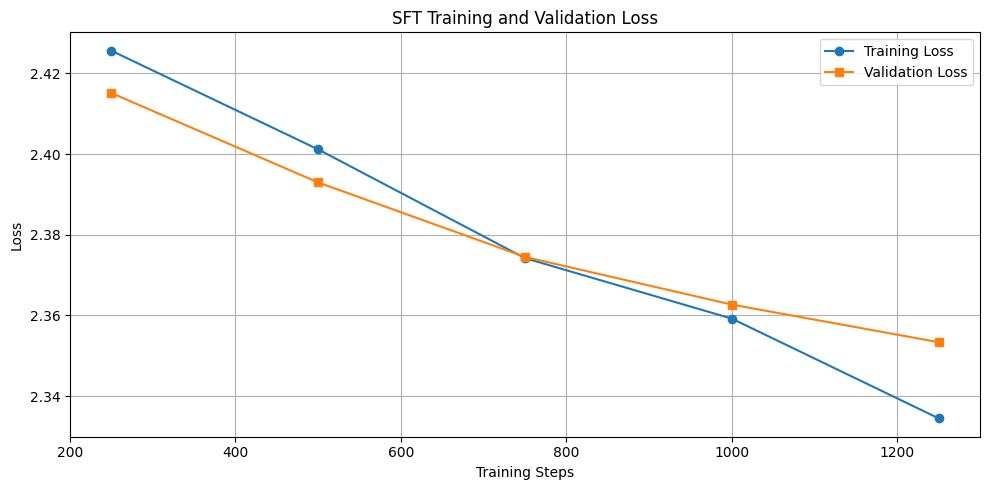

In [ ]:
steps = [x["step"] for x in sft_history]
train_losses = [x["train_loss"] for x in sft_history]
val_losses = [x["validation_loss"] for x in sft_history]

plt.figure(figsize=(10, 5))

plt.plot(
    steps,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    steps,
    val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("SFT Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    f"{PROJECT_DIR}/results/figures/sft_loss.png",
    dpi=200
)

plt.show()

**Step 20. Generate summaries after SFT**

In [ ]:
sft_model.eval()

sft_results = []

for i in range(5):

    post = eval_posts[i]

    summary = generate_summary(
        sft_model,
        post["prompt"]
    )

    sft_results.append({
        "index": i,
        "prompt": post["prompt"],
        "human_reference": post["summary"],
        "sft_summary": summary
    })

    print(f"\n========== POST {i+1} ==========")
    print("BEFORE SFT:", baseline_results[i]["base_model_summary"])
    print("AFTER SFT:", summary)
    print("HUMAN:", post["summary"])


========== POST 1 ==========
BEFORE SFT: I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going
AFTER SFT: boyfriend said hurtful things to me, I'm still hurt by them and I'm afraid to tell him his words hurt me.
HUMAN:  Boyfriend said some would stuff to me and I am so deeply hurt by them, but I'm scared bringing it up will result in another argument in which he ruins me once more.

========== POST 2 ==========
BEFORE SFT: I'm not sure if I should ask her to be my girlfriend or not.

I'm not sure if I should ask her to be my girlfriend.

I'm not sure if I should ask her to be my girlfriend.
AFTER SFT: I've been told that a girl has the same feeling I have, so I'm wondering if it's ok to just ask her to be my girlfriend.
HUMAN:  If we both know we like each other, and have really hit it off, can I just straight up ask her to be my girlfriend?

========== POST 3 ==========
BEFORE 

**Stage 2: Reward Model**

CLean old memory

In [ ]:
import gc
import torch

try:
    del sft_model
except NameError:
    pass

try:
    del optimizer
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleaned!")
print("GPU:", torch.cuda.get_device_name(0))
print("Available memory:", round(
    torch.cuda.mem_get_info()[0] / 1024**3, 2
), "GB")

GPU memory cleaned!
GPU: Tesla T4
Available memory: 12.7 GB


**Step 22 — Build the Reward Model architecture**

In [ ]:
class RewardModel(nn.Module):

    def __init__(self, sft_checkpoint):
        super().__init__()

        # Load the trained SFT model
        causal_lm = AutoModelForCausalLM.from_pretrained(
            sft_checkpoint,
            torch_dtype=torch.float32
        )

        # Extract transformer body, without LM head
        self.backbone = causal_lm.model

        # Get hidden dimension
        hidden_size = causal_lm.config.hidden_size

        # New scalar reward head
        self.reward_head = nn.Linear(hidden_size, 1)

        # Release language-model head
        del causal_lm

        # Gradient checkpointing for memory efficiency
        self.backbone.gradient_checkpointing_enable()

    def forward(self, input_ids, attention_mask):

        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        )

        # Last real (non-padding) token position
        last_indices = attention_mask.sum(dim=1) - 1

        batch_indices = torch.arange(
            input_ids.size(0),
            device=input_ids.device
        )

        # Extract final hidden states
        last_hidden = outputs.last_hidden_state[
            batch_indices,
            last_indices
        ]

        # One scalar reward per sequence
        rewards = self.reward_head(last_hidden)

        return rewards.squeeze(-1)

**Step 23 — Initialize Reward Model**

In [ ]:
SFT_CHECKPOINT = f"{PROJECT_DIR}/checkpoints/sft"

reward_model = RewardModel(
    SFT_CHECKPOINT
).to(DEVICE)

reward_model.train()

print("Reward model initialized!")
print(
    "Reward head:",
    reward_model.reward_head
)

print(
    "Trainable parameters:",
    sum(p.numel() for p in reward_model.parameters()
        if p.requires_grad)
)

**Step 24 — Create preference DataLoaders**

In [ ]:
REWARD_BATCH_SIZE = 8

reward_train_loader = DataLoader(
    pref_train,
    batch_size=REWARD_BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_pref,
    num_workers=0
)

reward_val_loader = DataLoader(
    pref_val,
    batch_size=REWARD_BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_pref,
    num_workers=0
)

print("Training batches:", len(reward_train_loader))
print("Validation batches:", len(reward_val_loader))

Training batches: 2500
Validation batches: 125


**Step 25 — Implement Bradley–Terry loss**

In [ ]:
def reward_loss_function(
    reward_model,
    batch
):
    chosen_ids = batch["chosen_ids"].to(DEVICE)
    chosen_mask = batch["chosen_mask"].to(DEVICE)

    rejected_ids = batch["rejected_ids"].to(DEVICE)
    rejected_mask = batch["rejected_mask"].to(DEVICE)

    # Reward for human-preferred summaries
    chosen_rewards = reward_model(
        chosen_ids,
        chosen_mask
    )

    # Reward for rejected summaries
    rejected_rewards = reward_model(
        rejected_ids,
        rejected_mask
    )

    # Bradley-Terry loss
    loss = -F.logsigmoid(
        chosen_rewards - rejected_rewards
    ).mean()

    return loss, chosen_rewards, rejected_rewards

**Step 26 — Implement validation accuracy**

In [ ]:
def evaluate_reward_model(
    model,
    loader
):
    model.eval()

    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():

        for batch in loader:

            loss, chosen, rejected = reward_loss_function(
                model,
                batch
            )

            correct += (
                chosen > rejected
            ).sum().item()

            total += chosen.numel()

            total_loss += loss.item() * chosen.numel()

    model.train()

    accuracy = correct / total
    average_loss = total_loss / total

    return average_loss, accuracy

**Step 27 — Initialize optimizer**

In [ ]:
reward_optimizer = torch.optim.AdamW(
    reward_model.parameters(),
    lr=1e-5
)

print("Reward optimizer initialized!")

**Step 28 — Train the Reward Model**

In [ ]:
# ==========================================
# REWARD MODEL TRAINING
# ==========================================

reward_history = []

reward_model.train()

reward_start_time = time.time()

running_reward_losses = []
reward_global_step = 0

for epoch in range(1):

    print(f"\nStarting Reward Model Epoch {epoch+1}/1")

    for batch in reward_train_loader:

        reward_global_step += 1

        reward_optimizer.zero_grad(set_to_none=True)

        # Forward pass and Bradley-Terry loss
        loss, chosen_rewards, rejected_rewards = (
            reward_loss_function(
                reward_model,
                batch
            )
        )

        # Backpropagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            reward_model.parameters(),
            1.0
        )

        # Update parameters
        reward_optimizer.step()

        running_reward_losses.append(loss.item())

        # Log every 250 steps
        if reward_global_step % 250 == 0:

            train_loss = float(
                np.mean(running_reward_losses)
            )

            running_reward_losses = []

            val_loss, val_accuracy = evaluate_reward_model(
                reward_model,
                reward_val_loader
            )

            elapsed = (
                time.time() - reward_start_time
            ) / 60

            record = {
                "step": reward_global_step,
                "train_loss": train_loss,
                "validation_loss": val_loss,
                "validation_accuracy": val_accuracy,
                "elapsed_minutes": elapsed
            }

            reward_history.append(record)

            print(
                f"Step {reward_global_step}/2500 | "
                f"Train Loss: {train_loss:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val Accuracy: {val_accuracy*100:.2f}% | "
                f"Time: {elapsed:.2f} min"
            )

            # Save training history
            with open(
                f"{PROJECT_DIR}/results/logs/reward_history.json",
                "w"
            ) as f:
                json.dump(reward_history, f, indent=4)

        # Recovery checkpoint every 500 steps
        if reward_global_step % 500 == 0:

            torch.save(
                {
                    "step": reward_global_step,
                    "model_state_dict": reward_model.state_dict(),
                    "optimizer_state_dict": reward_optimizer.state_dict(),
                    "history": reward_history
                },
                f"{PROJECT_DIR}/checkpoints/reward/reward_recovery.pt"
            )

    if running_reward_losses:
        print(
            "Final interval training loss:",
            float(np.mean(running_reward_losses))
        )

        running_reward_losses = []

total_reward_time = (
    time.time() - reward_start_time
) / 60

print("\n========== REWARD TRAINING COMPLETED ==========")
print("Total steps:", reward_global_step)
print("Training time:", round(total_reward_time, 2), "minutes")


Starting Reward Model Epoch 1/1
Step 250/2500 | Train Loss: 0.6847 | Val Loss: 0.6629 | Val Accuracy: 59.90% | Time: 13.82 min
Step 500/2500 | Train Loss: 0.6682 | Val Loss: 0.6517 | Val Accuracy: 61.70% | Time: 27.39 min
Step 750/2500 | Train Loss: 0.6525 | Val Loss: 0.6588 | Val Accuracy: 60.50% | Time: 41.30 min
Step 1000/2500 | Train Loss: 0.6396 | Val Loss: 0.6613 | Val Accuracy: 60.80% | Time: 54.64 min
Step 1250/2500 | Train Loss: 0.6283 | Val Loss: 0.6453 | Val Accuracy: 63.30% | Time: 68.13 min
Step 1500/2500 | Train Loss: 0.6129 | Val Loss: 0.6464 | Val Accuracy: 61.90% | Time: 81.68 min
Step 1750/2500 | Train Loss: 0.6060 | Val Loss: 0.6664 | Val Accuracy: 62.30% | Time: 95.58 min
Step 2000/2500 | Train Loss: 0.6039 | Val Loss: 0.6562 | Val Accuracy: 62.90% | Time: 109.48 min
Step 2250/2500 | Train Loss: 0.6194 | Val Loss: 0.6515 | Val Accuracy: 62.10% | Time: 123.49 min
Step 2500/2500 | Train Loss: 0.5974 | Val Loss: 0.6648 | Val Accuracy: 62.00% | Time: 137.37 min

======

**Step 29 — Save final Reward Model**

In [ ]:
REWARD_CHECKPOINT = f"{PROJECT_DIR}/checkpoints/reward"

os.makedirs(REWARD_CHECKPOINT, exist_ok=True)

torch.save(
    reward_model.state_dict(),
    f"{REWARD_CHECKPOINT}/reward_model.pt"
)

with open(
    f"{REWARD_CHECKPOINT}/config.json",
    "w"
) as f:
    json.dump(
        {
            "base_model": MODEL_NAME,
            "initial_checkpoint": SFT_CHECKPOINT,
            "hidden_size": reward_model.reward_head.in_features,
            "training_steps": reward_global_step,
            "learning_rate": 1e-5,
            "batch_size": 8,
            "epochs": 1
        },
        f,
        indent=4
    )

print("Final Reward Model saved!")

Final Reward Model saved!


# Step 30 — Plot training loss

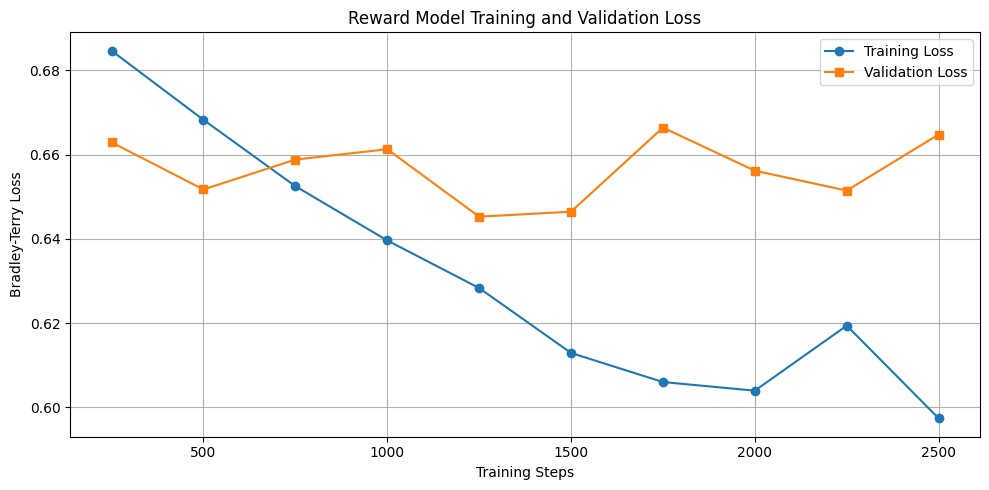

In [ ]:
reward_steps = [
    x["step"] for x in reward_history
]

reward_train_losses = [
    x["train_loss"] for x in reward_history
]

reward_val_losses = [
    x["validation_loss"] for x in reward_history
]

plt.figure(figsize=(10, 5))

plt.plot(
    reward_steps,
    reward_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    reward_steps,
    reward_val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Bradley-Terry Loss")
plt.title("Reward Model Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    f"{PROJECT_DIR}/results/figures/reward_loss.png",
    dpi=200
)

plt.show()

**Step 31 — Plot validation accuracy**

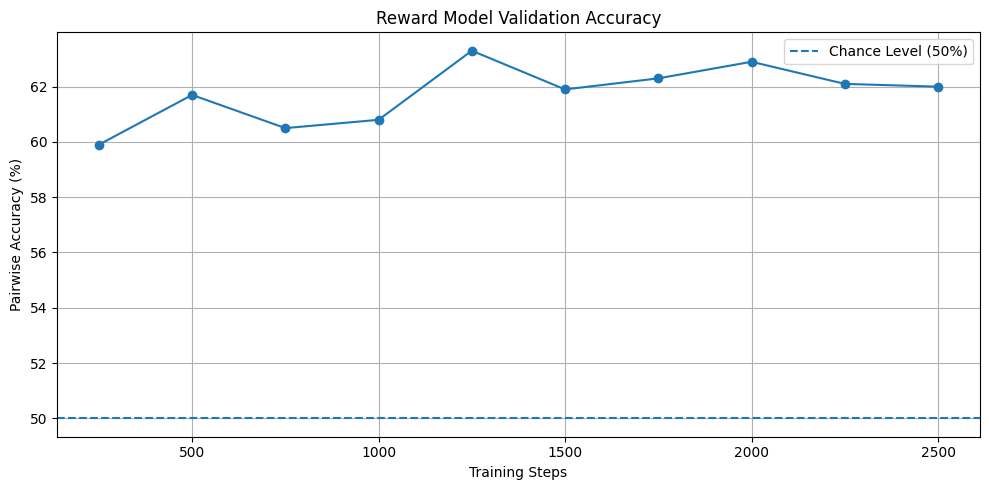

In [ ]:
reward_accuracies = [
    x["validation_accuracy"] * 100
    for x in reward_history
]

plt.figure(figsize=(10, 5))

plt.plot(
    reward_steps,
    reward_accuracies,
    marker="o"
)

plt.axhline(
    50,
    linestyle="--",
    label="Chance Level (50%)"
)

plt.xlabel("Training Steps")
plt.ylabel("Pairwise Accuracy (%)")
plt.title("Reward Model Validation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    f"{PROJECT_DIR}/results/figures/reward_accuracy.png",
    dpi=200
)

plt.show()

**Step 32 — Final Reward Model verification**

In [ ]:
final_reward_loss, final_reward_accuracy = evaluate_reward_model(
    reward_model,
    reward_val_loader
)

print("\n========== FINAL REWARD MODEL RESULTS ==========")

print("Final validation loss:", round(final_reward_loss, 4))

print(
    "Final pairwise accuracy:",
    round(final_reward_accuracy * 100, 2),
    "%"
)

print("Training steps:", reward_global_step)

print("Training time:", round(total_reward_time, 2), "minutes")

print(
    "Checkpoint exists:",
    os.path.exists(
        f"{REWARD_CHECKPOINT}/reward_model.pt"
    )
)

# Save final metrics
reward_final_results = {
    "validation_loss": final_reward_loss,
    "pairwise_accuracy": final_reward_accuracy,
    "training_steps": reward_global_step,
    "training_time_minutes": total_reward_time
}

with open(
    f"{PROJECT_DIR}/results/reward_final_results.json",
    "w"
) as f:
    json.dump(reward_final_results, f, indent=4)

print("\nSTAGE 2 COMPLETED!")


========== FINAL REWARD MODEL RESULTS ==========
Final validation loss: 0.6648
Final pairwise accuracy: 62.0 %
Training steps: 2500
Training time: 137.73 minutes
Checkpoint exists: True

STAGE 2 COMPLETED!


**Part 6 — Stage 3: PPO**

**Step 33 — Restore all trained components**

In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))

['GENAI_Assignment_03']


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GENAI_Assignment_03"

print("Project exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print(os.listdir(PROJECT_DIR))

Project exists: True
['checkpoints', 'app', 'results']


In [ ]:
for root, dirs, files in os.walk(PROJECT_DIR):

    if "config.json" in files and "model.safetensors" in files:
        print("SFT CHECKPOINT:", root)

    if "reward_model.pt" in files:
        print("REWARD CHECKPOINT:", root)

In [ ]:
import os

checkpoint_root = f"{PROJECT_DIR}/checkpoints"

for folder in ["sft", "reward", "ppo"]:

    path = os.path.join(checkpoint_root, folder)

    print(f"\n========== {folder.upper()} ==========")

    if os.path.exists(path):
        for root, dirs, files in os.walk(path):
            print("Folder:", root)
            print("Files:", files)
    else:
        print("Folder does not exist!")


========== SFT ==========
Folder: /content/drive/MyDrive/GENAI_Assignment_03/checkpoints/sft
Files: []

========== REWARD ==========
Folder: /content/drive/MyDrive/GENAI_Assignment_03/checkpoints/reward
Files: []

========== PPO ==========
Folder: /content/drive/MyDrive/GENAI_Assignment_03/checkpoints/ppo
Files: []


In [ ]:
import os
import shutil

PROJECT_DIR = "/content/drive/MyDrive/GENAI_Assignment_03"

SFT_CHECKPOINT = f"{PROJECT_DIR}/checkpoints/sft"
REWARD_CHECKPOINT = f"{PROJECT_DIR}/checkpoints/reward"

os.makedirs(SFT_CHECKPOINT, exist_ok=True)
os.makedirs(REWARD_CHECKPOINT, exist_ok=True)

DRIVE_ROOT = "/content/drive/MyDrive"

# SFT model and tokenizer files
sft_files = [
    "config.json",
    "generation_config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json",
    "special_tokens_map.json",
    "vocab.json",
    "merges.txt"
]

for filename in sft_files:
    source = os.path.join(DRIVE_ROOT, filename)

    if os.path.isfile(source):
        shutil.copy2(
            source,
            os.path.join(SFT_CHECKPOINT, filename)
        )
        print("SFT copied:", filename)

# Reward model files
reward_files = [
    "reward_model.pt",
    "reward_recovery.pt"
]

for filename in reward_files:
    source = os.path.join(DRIVE_ROOT, filename)

    if os.path.isfile(source):
        shutil.copy2(
            source,
            os.path.join(REWARD_CHECKPOINT, filename)
        )
        print("Reward copied:", filename)

print("\nSFT folder:", os.listdir(SFT_CHECKPOINT))
print("\nReward folder:", os.listdir(REWARD_CHECKPOINT))


SFT folder: []

Reward folder: []


In [ ]:
required_sft = [
    "config.json",
    "model.safetensors",
    "tokenizer_config.json"
]

required_reward = [
    "reward_model.pt"
]

sft_ok = all(
    os.path.isfile(os.path.join(SFT_CHECKPOINT, f))
    for f in required_sft
)

reward_ok = all(
    os.path.isfile(os.path.join(REWARD_CHECKPOINT, f))
    for f in required_reward
)

print("SFT checkpoint:", sft_ok)
print("Reward checkpoint:", reward_ok)

if sft_ok and reward_ok:
    print("\nBOTH CHECKPOINTS RESTORED SUCCESSFULLY!")
else:
    print("\nSome files are still missing. Check the folder listings.")

SFT checkpoint: False
Reward checkpoint: False

Some files are still missing. Check the folder listings.
